# 01 · Data preparation

**Goal:** turn the raw indicator file into a clean, model-ready dataset for the Horizon Health & Development Foundation case.

Steps:
1. Load and sanity-check the data (types, duplicates, ranges).
2. Find implausible values and data errors.
3. Find things that would bias an unsupervised analysis (coverage gaps, skew, outliers, redundant indicators, different units).
4. Fix what can be fixed, flag what cannot, and save two files:
   * `data/country_data_clean.csv`: corrected values on their original scale plus flag columns (used for interpretation).
   * `data/country_features_model.csv`: transformed and standardised features (used for PCA and clustering).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
Path("data").mkdir(exist_ok=True)

raw = pd.read_csv("country_data.csv", index_col="country")
print(raw.shape)
raw.head()

(167, 9)


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
country,,,,,,,,,
Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


## 1. Basic checks

In [2]:
print("Missing values:", raw.isna().sum().sum())
print("Duplicate countries:", raw.index.duplicated().sum())
print("Duplicate rows:", raw.duplicated().sum())
print(raw.dtypes.value_counts())
raw.describe().T.round(2)

Missing values: 0
Duplicate countries: 0
Duplicate rows: 0
float64    7
int64      2
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
child_mort,167.0,38.27,40.33,2.60,8.25,19.30,62.10,208.00
exports,167.0,41.11,27.41,0.11,23.80,35.00,51.35,200.00
health,167.0,6.82,2.75,1.81,4.92,6.32,8.60,17.90
imports,167.0,46.89,24.21,0.07,30.20,43.30,58.75,174.00
income,167.0,17144.69,19278.07,609.00,3355.00,9960.00,22800.00,125000.00
inflation,167.0,7.78,10.57,-4.21,1.81,5.39,10.75,104.00
life_expec,167.0,70.56,8.89,32.10,65.30,73.10,76.80,82.80
total_fer,167.0,2.95,1.51,1.15,1.80,2.41,3.88,7.49
gdpp,167.0,12964.16,18328.70,231.00,1330.00,4660.00,14050.00,105000.00


No missing values, no duplicates, all numeric. The file is technically clean, so the problems we are looking for are *content* problems.

## 2. Plausibility: extreme values per indicator

In [3]:
extremes = pd.DataFrame({
    c: [", ".join(f"{k} ({v:g})" for k, v in raw[c].nlargest(3).items()),
        ", ".join(f"{k} ({v:g})" for k, v in raw[c].nsmallest(3).items())]
    for c in raw.columns}, index=["highest 3", "lowest 3"]).T
extremes

,highest 3,lowest 3
child_mort,"Haiti (208), Sierra Leone (160), Chad (150)","Iceland (2.6), Luxembourg (2.8), Singapore (2.8)"
exports,"Singapore (200), Luxembourg (175), Malta (153)","Myanmar (0.109), Timor-Leste (2.2), Eritrea (4..."
health,"United States (17.9), Micronesia, Fed. Sts. (1...","Qatar (1.81), Myanmar (1.97), Pakistan (2.2)"
imports,"Singapore (174), Malta (154), Luxembourg (142)","Myanmar (0.0659), Brazil (11.8), Japan (13.6)"
income,"Qatar (125000), Luxembourg (91700), Brunei (80...","Congo, Dem. Rep. (609), Liberia (700), Burundi..."
inflation,"Nigeria (104), Venezuela (45.9), Mongolia (39.2)","Seychelles (-4.21), Ireland (-3.22), Japan (-1.9)"
life_expec,"Japan (82.8), Singapore (82.7), Switzerland (8...","Haiti (32.1), Lesotho (46.5), Central African ..."
total_fer,"Niger (7.49), Chad (6.59), Mali (6.55)","Singapore (1.15), South Korea (1.23), Hungary ..."
gdpp,"Luxembourg (105000), Norway (87800), Switzerla...","Burundi (231), Liberia (327), Congo, Dem. Rep...."


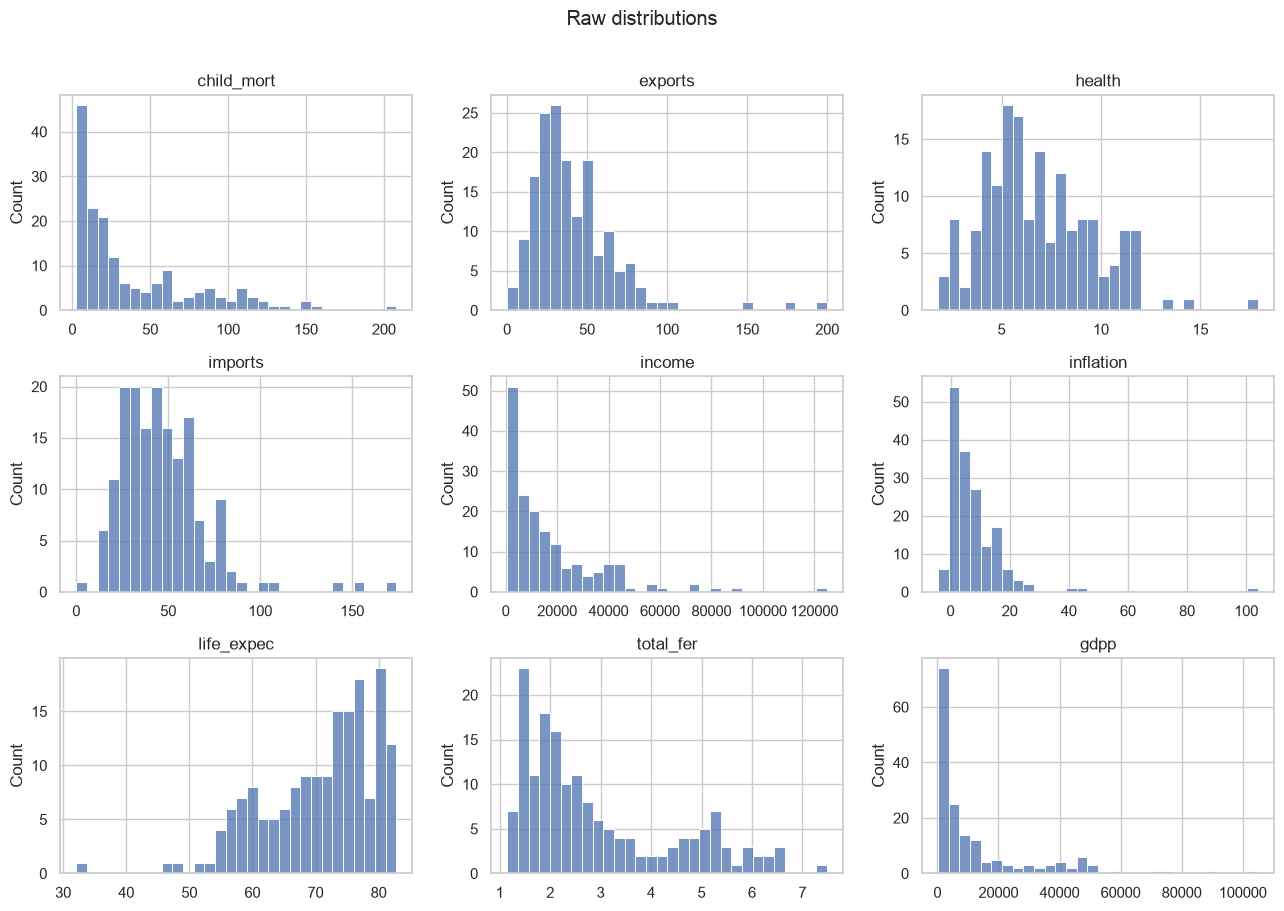

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, c in zip(axes.ravel(), raw.columns):
    sns.histplot(raw[c], ax=ax, bins=30)
    ax.set_title(c)
    ax.set_xlabel("")
fig.suptitle("Raw distributions", y=1.01)
plt.tight_layout()

### Findings

| Country | Issue | Assessment | Action |
|---|---|---|---|
| **Myanmar** | `exports` = 0.11 % and `imports` = 0.07 % of GDP | Impossible for a real economy (next lowest values are 2 % and 12 %). Almost certainly a data or unit error. | Set to missing and impute with the median of the poorest third of countries. Flagged. |
| **Nigeria** | `inflation` = 104 % | Far above every other country except Venezuela (46 %). Nigeria had no hyperinflation in this period. The variable is the GDP deflator, so a statistical revision (e.g. Nigeria's 2014 GDP rebasing) is a likely cause. | Set to missing and impute like Myanmar. Flagged. |
| **Haiti** | `child_mort` = 208, `life_expec` = 32 years | Real, but driven by the 2010 earthquake (an acute shock rather than the structural level). | Keep (the need is real), flag as *shock year*, and discuss it in the robustness section. |
| Venezuela, Mongolia | `inflation` 46 % / 39 % | Plausible for the period (high inflation, commodity boom). | Keep, damped by winsorising (see below). |
| Singapore, Luxembourg, Malta | `exports` / `imports` > 100 % of GDP | Plausible: re-export hubs. They will form their own group and must not distort the others. | Keep, damped by winsorising. |
| Micronesia, Sierra Leone, Liberia | `health` > 11 % of GDP | Plausible: small economies whose health budgets are largely donor-funded. This is useful information for programme B. | Keep. |


In [5]:
clean = raw.copy()
clean["flag_imputed"] = ""
clean["flag_note"] = ""

clean.loc["Myanmar", ["exports", "imports"]] = np.nan
clean.loc["Nigeria", "inflation"] = np.nan

# Peer group for imputation: the poorest third of countries by GDP per capita
peers = clean[clean["gdpp"] <= clean["gdpp"].quantile(1/3)]
for col in ["exports", "imports", "inflation"]:
    missing = clean[col].isna()
    clean.loc[missing, col] = peers[col].median()
    clean.loc[missing, "flag_imputed"] += col + " "

clean.loc["Myanmar", "flag_note"] = "trade values implausible (<0.2% of GDP), imputed"
clean.loc["Nigeria", "flag_note"] = "inflation 104% likely revision artefact, imputed"
clean.loc["Haiti", "flag_note"] = "2010 earthquake: mortality and life expectancy reflect an acute shock"
clean["flag_imputed"] = clean["flag_imputed"].str.strip()

clean.loc[["Myanmar", "Nigeria", "Haiti"]]

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,flag_imputed,flag_note
country,,,,,,,,,,,
Myanmar,64.4,23.8,1.97,40.3,3720,7.04,66.8,2.41,988,exports imports,"trade values implausible (<0.2% of GDP), imputed"
Nigeria,130.0,25.3,5.07,17.4,5150,8.79,60.5,5.84,2330,inflation,"inflation 104% likely revision artefact, imputed"
Haiti,208.0,15.3,6.91,64.7,1500,5.45,32.1,3.33,662,,2010 earthquake: mortality and life expectancy...


## 3. Things that would bias an unsupervised analysis

### 3.1 Coverage gap
Several countries that would be obvious candidates for a health foundation are **not in the data at all**. No algorithm can recommend them.

In [6]:
watchlist = ["Somalia", "South Sudan", "Ethiopia", "Zimbabwe", "Syria", "North Korea", "Yemen", "Nigeria", "Afghanistan"]
pd.Series({c: c in raw.index for c in watchlist}, name="in dataset").to_frame()

,in dataset
Somalia,False
South Sudan,False
Ethiopia,False
Zimbabwe,False
Syria,False
North Korea,False
Yemen,True
Nigeria,True
Afghanistan,True


Somalia, South Sudan, Ethiopia, Zimbabwe, Syria and North Korea are missing. This has to be stated to the board as a limitation: the shortlist is *"the neediest countries in this dataset"*, not *"in the world"*.

### 3.2 Units and skew
Income and GDP are in USD (up to 125,000), while the other indicators are percentages, years or rates. Distance-based methods (k-means) would be driven almost entirely by income if we did not scale. Income, GDP per capita and child mortality are also strongly right-skewed: the difference between 500 and 2,000 USD matters far more for living conditions than the difference between 50,000 and 51,500 USD.

In [7]:
skew = raw.skew().sort_values(ascending=False).round(2)
skew.to_frame("skewness")

,skewness
inflation,5.15
exports,2.45
income,2.23
gdpp,2.22
imports,1.91
child_mort,1.45
total_fer,0.97
health,0.71
life_expec,-0.97


### 3.3 Redundant indicators

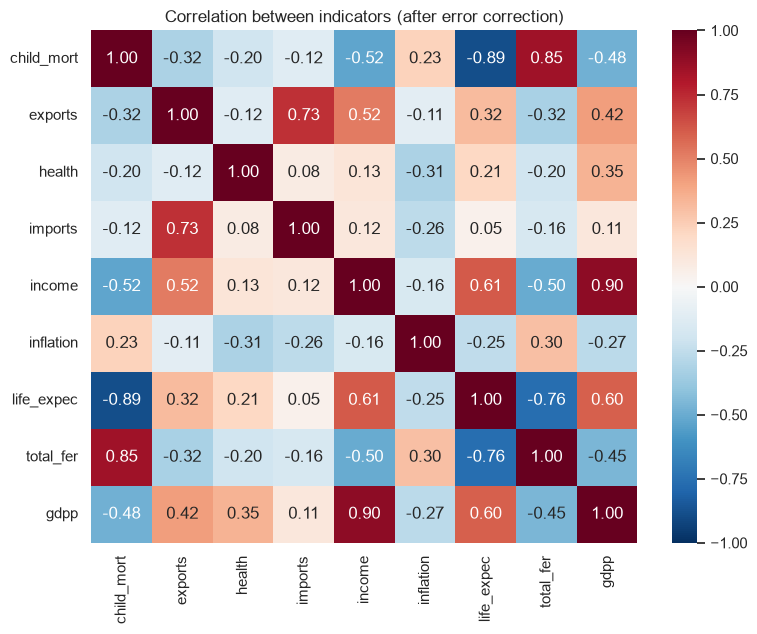

In [8]:
plt.figure(figsize=(8, 6.5))
sns.heatmap(clean[raw.columns].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlation between indicators (after error correction)")
plt.tight_layout()

Three groups of indicators move together:
* **Health/demography:** child mortality, life expectancy and fertility (|r| ≈ 0.76 to 0.89).
* **Wealth:** income and GDP per capita (r = 0.90).
* **Trade openness:** exports and imports (r = 0.74).

If we clustered on all nine raw columns, "health/demography" would effectively count three times and "wealth" twice. We handle this in the analysis with **PCA**: it merges correlated indicators into shared components, so each underlying dimension is counted once.

## 4. Transformations for modelling

1. **Log-transform** `income`, `gdpp` and `child_mort` (multiplicative scales, heavy right tail).
2. **Winsorise** `exports`, `imports`, `inflation` and `health` at the 2.5th and 97.5th percentiles so that a few trade hubs or high-inflation countries cannot pull the cluster centres.
3. **Standardise** all nine features (mean 0, standard deviation 1) so that every indicator starts with equal weight.

In [9]:
features = clean[raw.columns].copy()

for col in ["income", "gdpp", "child_mort"]:
    features[col] = np.log(features[col])

for col in ["exports", "imports", "inflation", "health"]:
    lo, hi = features[col].quantile([0.025, 0.975])
    n_clipped = ((features[col] < lo) | (features[col] > hi)).sum()
    print(f"{col:10s} clipped to [{lo:.1f}, {hi:.1f}]  ({n_clipped} countries affected)")
    features[col] = features[col].clip(lo, hi)

model = pd.DataFrame(StandardScaler().fit_transform(features), index=features.index, columns=features.columns)
model.describe().T[["mean", "std", "min", "max"]].round(2)

exports    clipped to [10.1, 92.8]  (10 countries affected)
imports    clipped to [17.2, 99.7]  (10 countries affected)
inflation  clipped to [-1.0, 23.5]  (10 countries affected)
health     clipped to [2.5, 11.9]  (10 countries affected)


,mean,std,min,max
child_mort,-0.0,1.0,-1.81,1.98
exports,-0.0,1.0,-1.42,2.53
health,0.0,1.0,-1.66,2.00
imports,0.0,1.0,-1.47,2.72
income,0.0,1.0,-2.21,2.14
inflation,0.0,1.0,-1.23,2.56
life_expec,0.0,1.0,-4.34,1.38
total_fer,0.0,1.0,-1.19,3.01
gdpp,0.0,1.0,-2.04,2.05


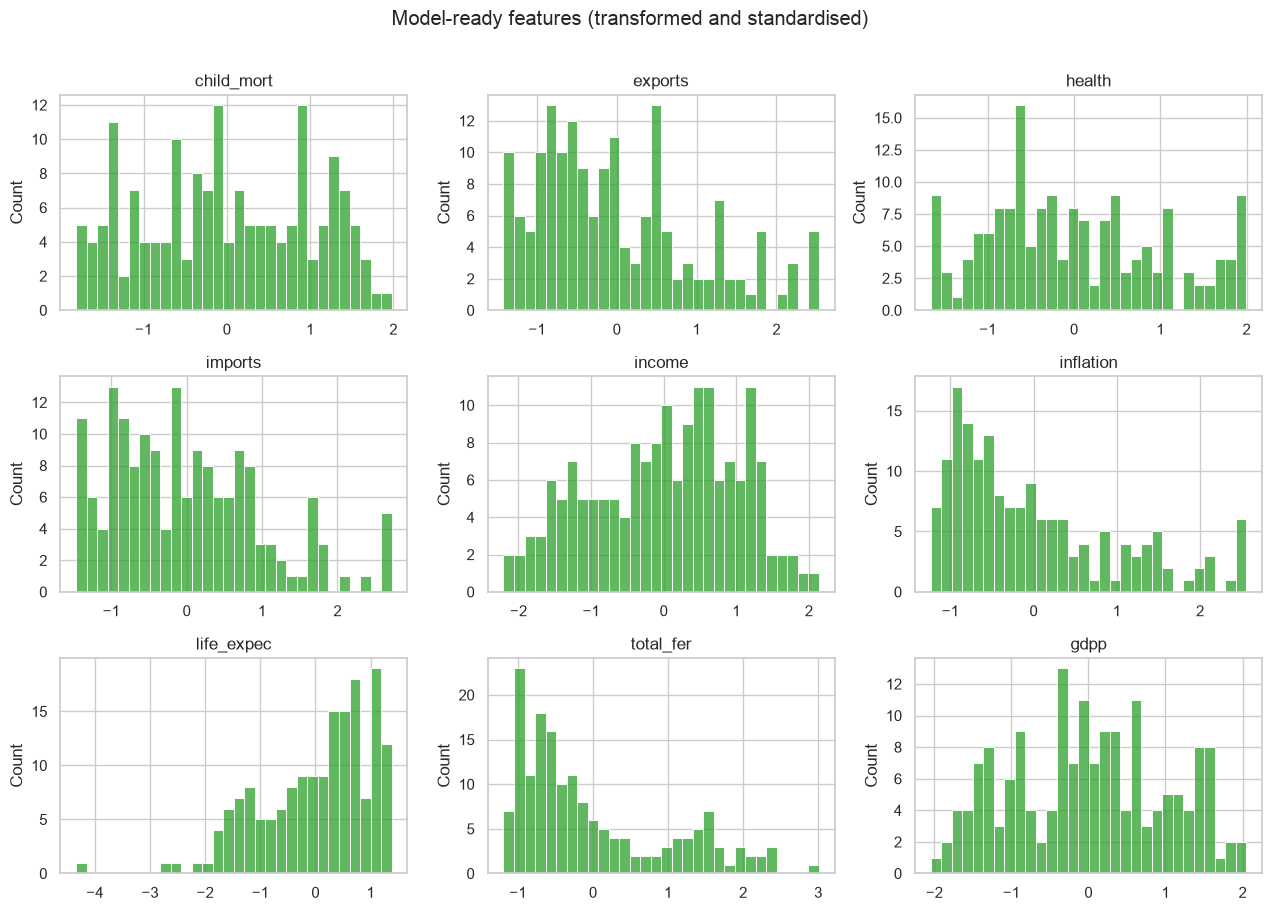

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, c in zip(axes.ravel(), model.columns):
    sns.histplot(model[c], ax=ax, bins=30, color="tab:green")
    ax.set_title(c)
    ax.set_xlabel("")
fig.suptitle("Model-ready features (transformed and standardised)", y=1.01)
plt.tight_layout()

## 5. Save

In [11]:
clean.to_csv("data/country_data_clean.csv")
model.to_csv("data/country_features_model.csv")
print("saved:", clean.shape, model.shape)

saved: (167, 11) (167, 9)


## Summary

* The file had no technical errors but **two content errors** (Myanmar trade, Nigeria inflation), which were imputed and flagged.
* **Haiti** is a real but shock-driven extreme. It is kept and discussed later.
* **Six crisis countries are missing** from the data. This limits what we can claim.
* Skew, different units and redundant indicators were handled by log transforms, winsorising and standardisation; the remaining redundancy is handled by PCA in `02_analysis.ipynb`.
